# Expérience 2 — auto-encodeur variationnel sur CAMUS

Ce notebook reconstruit des coupes d'échocardiographie 2D (jeu CAMUS) avec un auto-encodeur variationnel MONAI `AutoencoderKL`. Il est conçu pour être comparé à l'expérience 1, `assignment-2-camus.ipynb`.

Les deux expériences partagent la graine, le découpage par patient et la normalisation. L'expérience 2 change la largeur du réseau, la taille du code latent et le terme de reconstruction.

| | Expérience 1 | Expérience 2 |
| --- | --- | --- |
| Images | `camus_64`, 1 canal, intensités dans [0, 1] | mêmes images, même normalisation |
| Découpage | 80 % / 10 % / 10 % par patient, graine 12345 | même découpage |
| Réseau | canaux (16, 32, 64, 64), latent 4×8×8 | canaux (32, 64, 128, 128), latent 8×8×8 |
| Perte | L1 + β KL, recherche sur β, montée progressive de β | MSE + β KL, β = 1e-4 constant |
| Optimiseur | Adam 1e-3, calendrier cosinus | Adam 1e-3, pas constant |

Quatre étapes : audit des données, architecture, perte et entraînement, évaluation (reconstructions, t-SNE, interpolation ED → ES).

Les poids vont dans `checkpoints/`, le GIF et le fichier de résultats dans `artifacts/`. Ces dossiers sont ignorés par git.

CAMUS doit être cité : S. Leclerc, E. Smistad, J. Pedrosa, A. Ostvik, et al., « Deep Learning for Segmentation using an Open Large-Scale Dataset in 2D Echocardiography », IEEE Transactions on Medical Imaging, vol. 38, n° 9, pp. 2198-2210, 2019, doi: 10.1109/TMI.2019.2900516.

In [1]:
%matplotlib inline

import json
import os
import random
import time
import zipfile
from collections import Counter
from io import BytesIO
from pathlib import Path
from urllib.request import urlopen

import matplotlib.pyplot as plt
import monai
import nibabel as nib
import numpy as np
import torch
import torch.nn as nn
from IPython.display import Image, Markdown, display
from matplotlib.animation import FuncAnimation
from monai.data import DataLoader
from monai.metrics import PSNRMetric, SSIMMetric
from monai.networks.nets import AutoencoderKL
from monai.utils import set_determinism
from sklearn.manifold import TSNE
from sklearn.model_selection import train_test_split
from torch.utils.data import Dataset as TorchDataset
from torchinfo import summary

print(f"PyTorch {torch.__version__}  |  MONAI {monai.__version__}  |  NumPy {np.__version__}")

PyTorch 2.15.0+cpu  |  MONAI 1.6.1  |  NumPy 2.5.4


In [2]:
SEED = 12345


def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    set_determinism(seed=seed)


set_seed(SEED)
try:
    torch.set_num_interop_threads(1)
except RuntimeError:
    pass
torch.set_num_threads(max(1, os.cpu_count() or 1))

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Périphérique : {device}")
print(f"Fils CPU utilisés par PyTorch : {torch.get_num_threads()}")

CHECKPOINT_DIR = Path("checkpoints")
ARTIFACT_DIR = Path("artifacts")
CHECKPOINT_DIR.mkdir(exist_ok=True)
ARTIFACT_DIR.mkdir(exist_ok=True)
CHECKPOINT_PATH = CHECKPOINT_DIR / "exp2_vae_best.pth"

Périphérique : cpu
Fils CPU utilisés par PyTorch : 8


## 1. Audit et préparation des données

`data_dir` pointe vers le dossier extrait `camus_64` (images 64×64, un canal). L'ordre de recherche est : la variable `CAMUS_DATA_ROOT` si elle est définie, puis `../camus_64`, puis `data/camus_64`. Si aucun dossier n'existe, le notebook télécharge `camus_64.zip` depuis le serveur du cours.

Chaque examen est une image `uint8`. On divise par 255 pour obtenir des intensités dans [0, 1], communes à tous les patients. Le tableau est transposé pour placer l'apex en haut de la figure. Le masque expert suit la même géométrie. Il sert plus loin à séparer l'erreur sur le cœur et sur le fond. Il n'est pas une cible de reconstruction.

In [3]:
if os.environ.get("CAMUS_DATA_ROOT"):
    root = Path(os.environ["CAMUS_DATA_ROOT"]).expanduser().resolve()
    data_dir = root if root.name.startswith("camus_") else root / "camus_64"
elif (Path("..") / "camus_64").resolve().is_dir():
    data_dir = (Path("..") / "camus_64").resolve()
elif (Path("data") / "camus_64").resolve().is_dir():
    data_dir = (Path("data") / "camus_64").resolve()
else:
    data_dir = (Path("..") / "camus_64").resolve()

if not data_dir.is_dir():
    zip_url = "https://www.creatis.insa-lyon.fr/~bernard/camus/camus_64.zip"
    print(f"{data_dir} est absent. Téléchargement de {zip_url}")
    data_dir.parent.mkdir(parents=True, exist_ok=True)
    with urlopen(zip_url, timeout=180) as response:
        payload = response.read()
    with zipfile.ZipFile(BytesIO(payload)) as archive:
        archive.extractall(data_dir.parent)
    print(f"Archive extraite dans {data_dir}")
else:
    print(f"Données locales : {data_dir}")

assert data_dir.is_dir(), f"Dossier CAMUS introuvable : {data_dir}"

Données locales : /home/cytech/info/IAV/camus_64


### Découpage par patient

Le découpage est 80 % / 10 % / 10 %, avec `random_state=12345`, comme dans l'expérience 1. On sépare les patients, pas les images : les quatre vues d'un cœur (2CH et 4CH, télédiastole ED et télésystole ES) restent dans le même sous-ensemble.

In [4]:
def subdirs(folder, join=True, prefix=None, suffix=None, sort=True):
    # Liste des sous-dossiers, comme dans le squelette du devoir.
    joiner = os.path.join if join else (lambda root, name: name)
    names = [
        joiner(folder, name)
        for name in os.listdir(folder)
        if os.path.isdir(os.path.join(folder, name))
        and (prefix is None or name.startswith(prefix))
        and (suffix is None or name.endswith(suffix))
    ]
    if sort:
        names.sort()
    return names


data_dir = data_dir.resolve()
keys = subdirs(data_dir, prefix="patient", join=False)
train_keys, val_and_test_keys = train_test_split(keys, train_size=0.8, random_state=SEED)
val_keys, test_keys = train_test_split(val_and_test_keys, test_size=0.5, random_state=SEED)
train_keys, val_keys, test_keys = sorted(train_keys), sorted(val_keys), sorted(test_keys)

assert set(train_keys).isdisjoint(val_keys)
assert set(train_keys).isdisjoint(test_keys)
assert set(val_keys).isdisjoint(test_keys)

example_image = data_dir / keys[0] / f"{keys[0]}_2CH_ED.nii.gz"
assert example_image.is_file(), f"Image introuvable : {example_image}"
print(f"Patients : entraînement {len(train_keys)}, validation {len(val_keys)}, test {len(test_keys)}")
print(f"Exemple lu : {example_image.name}")

Patients : entraînement 400, validation 50, test 50
Exemple lu : patient0001_2CH_ED.nii.gz


### Jeu de données

Les cadres sont mis en cache en mémoire. La cohorte tient en quelques dizaines de mégaoctets, et relire les NIfTI à chaque époque dominerait le temps CPU. La clé `view_instant` (`2CH_ED`, `2CH_ES`, `4CH_ED`, `4CH_ES`) servira à colorer l'espace latent. La fraction d'éjection et la qualité d'image sont lues dans les fichiers `Info_*.cfg` pour rester alignées sur l'expérience 1. Elles ne sont pas des cibles.

In [5]:
IMAGE_SIZE = 64
IN_CHANNELS = 1
VIEWS = ("2CH_ED", "2CH_ES", "4CH_ED", "4CH_ES")
LABEL_NAMES = {0: "fond", 1: "cavité VG", 2: "myocarde", 3: "oreillette gauche"}


def load_nifti(path):
    array = np.squeeze(nib.load(str(path)).get_fdata())
    if array.ndim != 2:
        raise ValueError(f"Image 2D attendue dans {path}, forme {array.shape}")
    return np.ascontiguousarray(array.T)


def read_info(path):
    info = {}
    if not path.exists():
        return info
    for line in path.read_text().splitlines():
        if ":" not in line:
            continue
        key, value = line.split(":", 1)
        info[key.strip()] = value.strip()
    return info


def build_records(patient_keys):
    records = []
    for patient in patient_keys:
        folder = data_dir / patient
        for view_instant in VIEWS:
            view, instant = view_instant.split("_")
            info = read_info(folder / f"Info_{view}.cfg")
            image = load_nifti(folder / f"{patient}_{view_instant}.nii.gz").astype(np.float32)
            if image.max() > 1:
                image = image / 255.0
            label = load_nifti(folder / f"{patient}_{view_instant}_gt.nii.gz").astype(np.int64)
            try:
                ef = float(info.get("EF", "nan"))
            except ValueError:
                ef = float("nan")
            records.append({
                "image": torch.from_numpy(image[None]),
                "label": torch.from_numpy(label),
                "patient": patient,
                "view": view,
                "instant": instant,
                "view_instant": view_instant,
                "ef": ef,
                "quality": info.get("ImageQuality", "NA"),
            })
    return records


class CamusDataset(TorchDataset):
    def __init__(self, records):
        self.records = records

    def __len__(self):
        return len(self.records)

    def __getitem__(self, index):
        return self.records[index]


print("Chargement des cadres NIfTI en mémoire...")
t0 = time.perf_counter()
train_dataset = CamusDataset(build_records(train_keys))
valid_dataset = CamusDataset(build_records(val_keys))
test_dataset = CamusDataset(build_records(test_keys))
print(
    f"{len(train_dataset) + len(valid_dataset) + len(test_dataset)} cadres "
    f"en cache en {time.perf_counter() - t0:.1f} s"
)

sample = train_dataset[0]
print(f"Image : {tuple(sample['image'].shape)}  [{float(sample['image'].min()):.3f}, {float(sample['image'].max()):.3f}]")
print(f"Masque : {tuple(sample['label'].shape)}  classes {torch.unique(sample['label']).tolist()}")
print("Convention des masques :", LABEL_NAMES)

Chargement des cadres NIfTI en mémoire...


2000 cadres en cache en 2.5 s
Image : (1, 64, 64)  [0.000, 1.000]
Masque : (64, 64)  classes [0, 1, 2, 3]
Convention des masques : {0: 'fond', 1: 'cavité VG', 2: 'myocarde', 3: 'oreillette gauche'}


### Chargeurs

`test_loader` est construit sur `test_dataset`. Le squelette du cours le construisait sur le jeu de validation, et les chiffres de test auraient alors été des chiffres de validation. Les assertions ci-dessous vérifient le nombre d'images et l'absence de patient commun.

In [6]:
BATCH_SIZE = 64

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
valid_loader = DataLoader(valid_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

print(f"Images d'entraînement : {len(train_loader.dataset)}")
print(f"Images de validation :  {len(valid_loader.dataset)}")
print(f"Images de test :        {len(test_loader.dataset)}")

assert test_loader.dataset is test_dataset
assert test_loader.dataset is not valid_dataset
assert len(test_loader.dataset) == len(test_dataset)
assert set(test_keys).isdisjoint(val_keys)
assert set(test_keys).isdisjoint(train_keys)
print("Le chargeur de test lit les patients tenus à l'écart. Effectif égal à la validation, patients différents.")

Images d'entraînement : 1600
Images de validation :  200
Images de test :        200
Le chargeur de test lit les patients tenus à l'écart. Effectif égal à la validation, patients différents.


### Contrôle des intensités et des vues

Toutes les images doivent être en niveaux de gris, de forme `(1, 64, 64)`, avec des valeurs dans [0, 1]. Les quatre couples vue / instant doivent être équilibrés, puisqu'un patient contribue exactement une image à chacun.

Forme unique : (1, 64, 64)   canal d'entrée in_channels=1
Intensités sur les trois sous-ensembles : [0.000, 1.000]
entraînement   {'2CH_ED': 400, '2CH_ES': 400, '4CH_ED': 400, '4CH_ES': 400}
validation     {'2CH_ED': 50, '2CH_ES': 50, '4CH_ED': 50, '4CH_ES': 50}
test           {'2CH_ED': 50, '2CH_ES': 50, '4CH_ED': 50, '4CH_ES': 50}


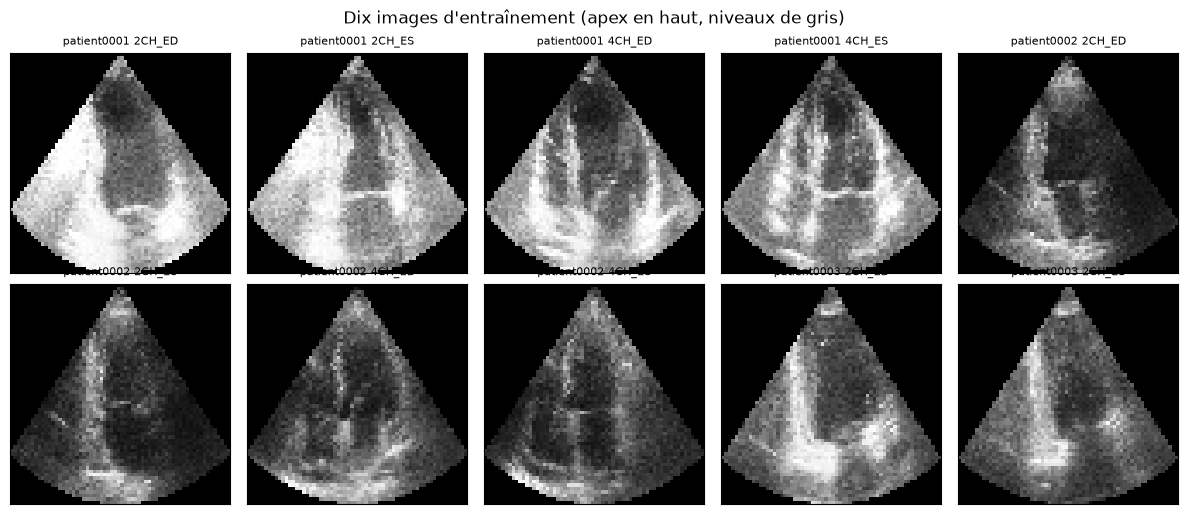

In [7]:
shapes = set()
mins, maxs = [], []
for subset in (train_dataset, valid_dataset, test_dataset):
    for record in subset.records:
        image = record["image"]
        shapes.add(tuple(image.shape))
        mins.append(float(image.min()))
        maxs.append(float(image.max()))

assert shapes == {(IN_CHANNELS, IMAGE_SIZE, IMAGE_SIZE)}, shapes
assert min(mins) >= 0.0 and max(maxs) <= 1.0
print(f"Forme unique : {shapes.pop()}   canal d'entrée in_channels={IN_CHANNELS}")
print(f"Intensités sur les trois sous-ensembles : [{min(mins):.3f}, {max(maxs):.3f}]")
for name, subset in (
    ("entraînement", train_dataset),
    ("validation", valid_dataset),
    ("test", test_dataset),
):
    counts = Counter(record["view_instant"] for record in subset.records)
    print(f"{name:14s} {dict(sorted(counts.items()))}")

fig, axes = plt.subplots(2, 5, figsize=(12, 5.2))
for ax, index in zip(axes.ravel(), range(10)):
    record = train_dataset[index]
    ax.imshow(record["image"][0].numpy(), cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"{record['patient']} {record['view_instant']}", fontsize=8)
    ax.set_xticks([])
    ax.set_yticks([])
fig.suptitle("Dix images d'entraînement (apex en haut, niveaux de gris)")
fig.tight_layout()
plt.show()

## 2. Architecture (`AutoencoderKL`)

Le modèle est un `AutoencoderKL` 2D (Rombach et al., diffusion latente ; Pinaya et al. pour l'IRM cérébrale). L'encodeur produit les paramètres d'une gaussienne diagonale. Un échantillon de cette gaussienne est décodé en une image.

`channels=(32, 64, 128, 128)` donne trois sous-échantillonnages : 64 → 32 → 16 → 8. Avec `latent_channels=8`, le code est un tenseur 8×8×8, soit 512 coefficients pour 4096 pixels (compression ×8). L'expérience 1 stockait 4×8×8 = 256 coefficients (compression ×16) dans un réseau plus étroit. L'expérience 2 a donc plus de capacité et un code un peu moins compact.

L'attention spatiale et les blocs non locaux sont désactivés, et chaque niveau n'a qu'un bloc résiduel : sur CPU, un réseau plus large avec de l'attention rendrait l'entraînement trop long pour une comparaison honnête. `norm_num_groups=32` divise tous les nombres de canaux.

In [8]:
CHANNELS = (32, 64, 128, 128)
LATENT_CHANNELS = 8
ATTENTION_LEVELS = (False,) * len(CHANNELS)
NORM_GROUPS = 32
NUM_RES_BLOCKS = 1

assert all(channel % NORM_GROUPS == 0 for channel in CHANNELS)
assert len(ATTENTION_LEVELS) == len(CHANNELS)


def build_vae(seed=SEED):
    set_seed(seed)
    model = AutoencoderKL(
        spatial_dims=2,
        in_channels=IN_CHANNELS,
        out_channels=1,
        num_res_blocks=NUM_RES_BLOCKS,
        channels=CHANNELS,
        attention_levels=ATTENTION_LEVELS,
        latent_channels=LATENT_CHANNELS,
        norm_num_groups=NORM_GROUPS,
        with_encoder_nonlocal_attn=False,
        with_decoder_nonlocal_attn=False,
    )
    return model.to(device)


model = build_vae(SEED)
print(summary(
    model,
    input_size=(BATCH_SIZE, IN_CHANNELS, IMAGE_SIZE, IMAGE_SIZE),
    depth=2,
    col_names=["input_size", "output_size", "num_params"],
    verbose=0,
    device="cpu",
))

with torch.no_grad():
    probe, mu, sigma = model(torch.zeros(1, IN_CHANNELS, IMAGE_SIZE, IMAGE_SIZE, device=device))

LATENT_SHAPE = tuple(mu.shape[1:])
downsamples = len(CHANNELS) - 1
expected_latent = (
    LATENT_CHANNELS,
    IMAGE_SIZE // 2**downsamples,
    IMAGE_SIZE // 2**downsamples,
)
assert LATENT_SHAPE == expected_latent, (LATENT_SHAPE, expected_latent)
assert tuple(sigma.shape[1:]) == LATENT_SHAPE
assert tuple(probe.shape) == (1, 1, IMAGE_SIZE, IMAGE_SIZE)

N_PARAMS = sum(parameter.numel() for parameter in model.parameters())
pixels = IN_CHANNELS * IMAGE_SIZE * IMAGE_SIZE
latent_size = int(np.prod(LATENT_SHAPE))
print(f"Reconstruction {tuple(probe.shape)}, moyenne latente {LATENT_SHAPE}, sigma {tuple(sigma.shape)}")
print(f"Paramètres entraînables : {N_PARAMS:,}")
print(f"Code latent : {latent_size} coefficients pour {pixels} pixels, compression ×{pixels / latent_size:.0f}")
print("Convolutions du goulot :")
for name in ("quant_conv_mu", "quant_conv_log_sigma", "post_quant_conv"):
    layer = getattr(model, name)
    conv = layer.conv if hasattr(layer, "conv") else layer
    print(
        f"  {name}: noyau {tuple(conv.kernel_size)}, "
        f"pas {tuple(conv.stride)}, padding {tuple(conv.padding)}"
    )

Layer (type:depth-idx)                   Input Shape               Output Shape              Param #
AutoencoderKL                            [64, 1, 64, 64]           [64, 1, 64, 64]           --
├─Encoder: 1-1                           [64, 1, 64, 64]           [64, 8, 8, 8]             --
│    └─ModuleList: 2-1                   --                        --                        805,736
├─Convolution: 1-2                       [64, 8, 8, 8]             [64, 8, 8, 8]             --
│    └─Conv2d: 2-2                       [64, 8, 8, 8]             [64, 8, 8, 8]             72
├─Convolution: 1-3                       [64, 8, 8, 8]             [64, 8, 8, 8]             --
│    └─Conv2d: 2-3                       [64, 8, 8, 8]             [64, 8, 8, 8]             72
├─Convolution: 1-4                       [64, 8, 8, 8]             [64, 8, 8, 8]             --
│    └─Conv2d: 2-4                       [64, 8, 8, 8]             [64, 8, 8, 8]             72
├─Decoder: 1-5                

### Lecture du goulot

Le résumé montre un encodeur qui se termine sur une grille spatiale 8×8, trois convolutions qui restent à cette taille, et un décodeur qui revient à une image 1×64×64.

Ces trois convolutions sont `quant_conv_mu`, `quant_conv_log_sigma` et `post_quant_conv`. Chacune a un noyau 1×1 : elles ne changent pas la taille spatiale. Les deux premières lisent les cartes de l'encodeur et produisent μ et log σ². L'implémentation MONAI borne la log-variance et renvoie σ = exp(log σ² / 2). `post_quant_conv` mélange le code échantillonné avant le décodeur.

Pendant l'entraînement, le décodeur reçoit z = μ + ε σ (astuce de reparamétrisation), pas le couple (μ, σ). À l'évaluation, on décodera μ, la moyenne a posteriori, pour que la reconstruction soit déterministe.

## 3. Perte et entraînement

Sous une vraisemblance gaussienne, l'ELBO négatif est une erreur quadratique plus la divergence de Kullback-Leibler entre q(z|x) et la loi normale standard. La perte minimisée ici est

$$L = \mathrm{MSE}(x, \hat{x}) + \beta \cdot \mathrm{KL}\big(q(z|x) \,\|\, \mathcal{N}(0, I)\big)$$

avec, pour une gaussienne diagonale, la KL sommée sur les coefficients latents puis moyennée sur le lot :

$$\mathrm{KL} = \frac{1}{2} \sum_i \big(\mu_i^2 + \sigma_i^2 - \log(\sigma_i^2) - 1\big)$$

La somme porte sur 8×8×8 = 512 coefficients. Une KL brute de quelques dizaines est donc attendue, alors que la MSE d'images dans [0, 1] vaut quelques centièmes. β est fixé à 1e-4 pour que le terme de reconstruction reste actif. Un β trop grand écrase le code vers le prior avant que le décodeur ait appris (effondrement du postérieur : la KL tombe à zéro et les reconstructions deviennent un secteur moyen).

L'expérience 1 minimisait une L1, faisait varier β, et le montait progressivement en début d'entraînement. Ici β est constant, pour isoler l'effet du terme MSE et du code 8×8×8. Les courbes de KL diront si cette valeur tient sans montée progressive.

L'optimiseur est Adam à 1e-3. Les gradients sont tronqués à 1. Le pas d'apprentissage reste constant (l'expérience 1 utilisait un calendrier cosinus). À chaque époque on enregistre la perte totale, la MSE et la KL, en entraînement et en validation. Le fichier `checkpoints/exp2_vae_best.pth` est réécrit chaque fois que la perte totale de validation atteint un nouveau minimum. L'évaluation recharge ces poids.

La validation décode μ. L'entraînement décode z = μ + ε σ. `AutoencoderKL.forward` échantillonne même en mode `eval`, ce qui rendrait la courbe de validation bruitée. On appelle donc `encode` et `decode` explicitement.

In [9]:
BETA = 1e-4
LR = 1e-3
N_EPOCHS = int(os.environ.get("CAMUS_EXP2_EPOCHS", "20"))
TRAIN = os.environ.get("CAMUS_EXP2_TRAIN", "1") not in {"0", "false", "False"}

mse_loss = nn.MSELoss(reduction="mean")


def kl_divergence(mu, sigma):
    sigma = sigma.clamp_min(1e-6)
    kl = 0.5 * torch.sum(
        mu.pow(2) + sigma.pow(2) - torch.log(sigma.pow(2)) - 1,
        dim=tuple(range(1, mu.ndim)),
    )
    return kl.mean()


def vae_loss(recon, target, mu, sigma, beta):
    recon_loss = mse_loss(recon, target)
    kl_loss = kl_divergence(mu, sigma)
    return recon_loss + beta * kl_loss, recon_loss, kl_loss


print(f"β = {BETA:.0e}   MSE + β·KL   époques = {N_EPOCHS}   TRAIN = {TRAIN}")

β = 1e-04   MSE + β·KL   époques = 20   TRAIN = True


In [10]:
CONFIG = {
    "spatial_dims": 2,
    "in_channels": IN_CHANNELS,
    "out_channels": 1,
    "channels": list(CHANNELS),
    "attention_levels": list(ATTENTION_LEVELS),
    "latent_channels": LATENT_CHANNELS,
    "latent_shape": list(LATENT_SHAPE),
    "norm_num_groups": NORM_GROUPS,
    "num_res_blocks": NUM_RES_BLOCKS,
    "beta": BETA,
    "recon_loss": "mse",
    "image_size": IMAGE_SIZE,
    "seed": SEED,
    "batch_size": BATCH_SIZE,
    "lr": LR,
}


def train_vae(model, n_epochs, beta, config, lr=LR):
    set_seed(SEED)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    history = {
        "train_total": [],
        "train_recon": [],
        "train_kl": [],
        "val_total": [],
        "val_recon": [],
        "val_kl": [],
        "beta": beta,
        "epochs": n_epochs,
        "recon": "mse",
    }
    best_score = float("inf")
    best_state = None
    best_epoch = 0
    clock = time.perf_counter()

    for epoch in range(n_epochs):
        model.train()
        totals = {"total": 0.0, "recon": 0.0, "kl": 0.0}
        seen = 0
        for batch in train_loader:
            images = batch["image"].to(device)
            optimizer.zero_grad(set_to_none=True)
            mu, sigma = model.encode(images)
            z = model.sampling(mu, sigma)
            recon = model.decode(z)
            total, recon_loss, kl_loss = vae_loss(recon, images, mu, sigma, beta)
            total.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            batch_size = images.size(0)
            totals["total"] += float(total.detach()) * batch_size
            totals["recon"] += float(recon_loss.detach()) * batch_size
            totals["kl"] += float(kl_loss.detach()) * batch_size
            seen += batch_size
        train_means = {key: value / seen for key, value in totals.items()}

        model.eval()
        totals = {"total": 0.0, "recon": 0.0, "kl": 0.0}
        seen = 0
        with torch.no_grad():
            for batch in valid_loader:
                images = batch["image"].to(device)
                mu, sigma = model.encode(images)
                recon = model.decode(mu)
                total, recon_loss, kl_loss = vae_loss(recon, images, mu, sigma, beta)
                batch_size = images.size(0)
                totals["total"] += float(total.detach()) * batch_size
                totals["recon"] += float(recon_loss.detach()) * batch_size
                totals["kl"] += float(kl_loss.detach()) * batch_size
                seen += batch_size
        val_means = {key: value / seen for key, value in totals.items()}

        history["train_total"].append(train_means["total"])
        history["train_recon"].append(train_means["recon"])
        history["train_kl"].append(train_means["kl"])
        history["val_total"].append(val_means["total"])
        history["val_recon"].append(val_means["recon"])
        history["val_kl"].append(val_means["kl"])

        saved = False
        if val_means["total"] < best_score:
            best_score = val_means["total"]
            best_epoch = epoch + 1
            best_state = {
                key: value.detach().cpu().clone()
                for key, value in model.state_dict().items()
            }
            history["best_epoch"] = best_epoch
            history["best_val"] = best_score
            torch.save(
                {
                    "state_dict": best_state,
                    "epoch": best_epoch,
                    "history": history,
                    "config": config,
                },
                CHECKPOINT_PATH,
            )
            saved = True

        flag = "  checkpoint" if saved else ""
        print(
            f"Époque {epoch + 1:02d}/{n_epochs}  "
            f"train {train_means['total']:.5f} (mse {train_means['recon']:.5f}, kl {train_means['kl']:.2f})  "
            f"val {val_means['total']:.5f} (mse {val_means['recon']:.5f}, kl {val_means['kl']:.2f})"
            f"{flag}"
        )

    history["seconds"] = time.perf_counter() - clock
    history["best_epoch"] = best_epoch
    history["best_val"] = best_score
    model.load_state_dict(best_state)
    # Dernière écriture : mêmes poids (le minimum de validation), courbes complètes.
    torch.save(
        {
            "state_dict": model.state_dict(),
            "epoch": best_epoch,
            "history": history,
            "config": config,
        },
        CHECKPOINT_PATH,
    )
    print(
        f"Meilleure époque {best_epoch}/{n_epochs}, "
        f"perte de validation {best_score:.6f}, "
        f"durée {history['seconds'] / 60:.1f} min."
    )
    print(f"Poids enregistrés dans {CHECKPOINT_PATH}.")
    return model, history


model = build_vae(SEED)
if TRAIN:
    model, history = train_vae(model, N_EPOCHS, BETA, CONFIG, lr=LR)
else:
    payload = torch.load(CHECKPOINT_PATH, map_location=device, weights_only=False)
    model.load_state_dict(payload["state_dict"])
    history = payload["history"]
    print(f"Poids rechargés : {CHECKPOINT_PATH} (époque {history['best_epoch']})")

Époque 01/20  train 0.08851 (mse 0.08091, kl 75.94)  val 0.03386 (mse 0.03093, kl 29.30)  checkpoint


Époque 02/20  train 0.03147 (mse 0.02824, kl 32.29)  val 0.02033 (mse 0.01698, kl 33.51)  checkpoint


Époque 03/20  train 0.02319 (mse 0.01977, kl 34.26)  val 0.01717 (mse 0.01384, kl 33.30)  checkpoint


Époque 04/20  train 0.02118 (mse 0.01808, kl 30.95)  val 0.01595 (mse 0.01310, kl 28.46)  checkpoint


Époque 05/20  train 0.01933 (mse 0.01666, kl 26.67)  val 0.01437 (mse 0.01180, kl 25.69)  checkpoint


Époque 06/20  train 0.01794 (mse 0.01547, kl 24.75)  val 0.01404 (mse 0.01177, kl 22.77)  checkpoint


... (10 outputs left out)

Époque 17/20  train 0.01150 (mse 0.00885, kl 26.48)  val 0.00913 (mse 0.00660, kl 25.31)


Époque 18/20  train 0.01158 (mse 0.00894, kl 26.46)  val 0.00874 (mse 0.00611, kl 26.27)  checkpoint


Époque 19/20  train 0.01128 (mse 0.00867, kl 26.10)  val 0.00848 (mse 0.00624, kl 22.37)  checkpoint


Époque 20/20  train 0.01099 (mse 0.00841, kl 25.79)  val 0.00932 (mse 0.00623, kl 30.81)
Meilleure époque 19/20, perte de validation 0.008481, durée 30.5 min.
Poids enregistrés dans checkpoints/exp2_vae_best.pth.


### Courbes

La MSE d'entraînement reconstruit un échantillon bruité z, la MSE de validation reconstruit μ. La courbe de validation peut donc se placer un peu sous la courbe d'entraînement sans que cela indique un sur-apprentissage. Un sur-apprentissage se lirait comme une validation qui remonte pendant que l'entraînement continue de descendre.

La KL part d'une valeur élevée (un encodeur aléatoire est loin de la normale standard) puis doit se stabiliser à une valeur finie et non nulle. Une KL qui tombe à zéro signale un effondrement du postérieur. Une KL qui diverge signale un postérieur qui s'éloigne du prior.

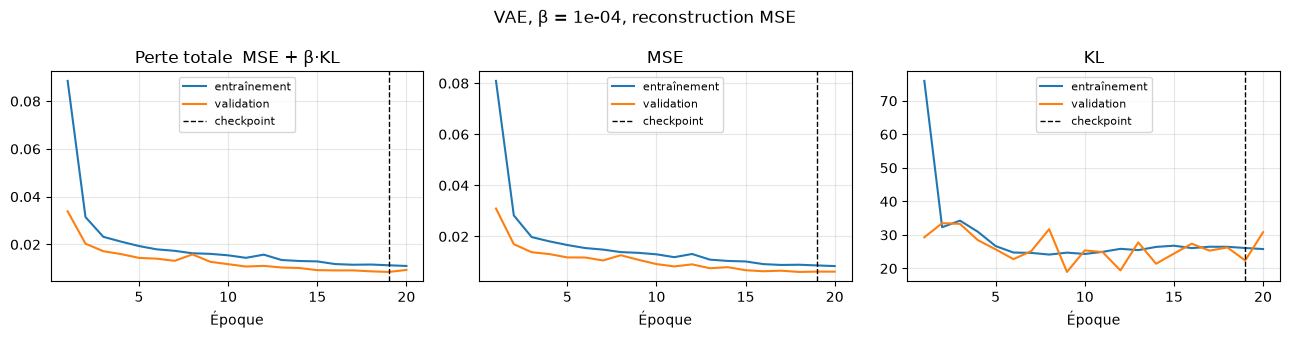

In [11]:
def plot_history(history):
    epochs = np.arange(1, len(history["train_total"]) + 1)
    fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
    series = (
        ("total", "Perte totale  MSE + β·KL"),
        ("recon", "MSE"),
        ("kl", "KL"),
    )
    for ax, (key, title) in zip(axes, series):
        ax.plot(epochs, history[f"train_{key}"], label="entraînement")
        ax.plot(epochs, history[f"val_{key}"], label="validation")
        ax.axvline(history["best_epoch"], color="black", ls="--", lw=1, label="checkpoint")
        ax.set_title(title)
        ax.set_xlabel("Époque")
        ax.grid(True, alpha=0.3)
        ax.legend(fontsize=8)
    fig.suptitle(f"VAE, β = {history['beta']:.0e}, reconstruction MSE")
    fig.tight_layout()
    plt.show()


plot_history(history)

## 4. Évaluation

Les métriques sont calculées sur les patients de test, en décodant μ. La MSE et le PSNR utilisent la sortie brute du décodeur, donc une valeur hors de [0, 1] est pénalisée. Le PSNR est celui de MONAI `PSNRMetric` avec un pic de 1. Le SSIM est celui de MONAI `SSIMMetric`, fenêtre de 7, après bornage à [0, 1], comme dans l'expérience 1. Le MAE est rapporté pour la même raison.

Le masque expert sépare l'erreur quadratique sur le cœur (labels 1, 2 et 3) et sur le fond. Le fond est en grande partie noir, donc facile : une MSE globale basse peut cacher une cavité floue.

MSE moyenne sur les 200 images de test : 0.00765 ± 0.00538
MAE test :  0.055 ± 0.016
PSNR test : 21.70 ± 1.92 dB
SSIM test : 0.445 ± 0.065
MSE sur le cœur : 0.01073 ± 0.00486
MSE sur le fond : 0.00678 ± 0.00624


### MSE et PSNR de test par vue et par instant

| Vue / instant | n | MSE | PSNR (dB) |
| --- | --- | --- | --- |
| 2CH_ED | 50 | 0.00741 | 21.82 |
| 2CH_ES | 50 | 0.00681 | 22.28 |
| 4CH_ED | 50 | 0.00851 | 21.15 |
| 4CH_ES | 50 | 0.00786 | 21.54 |

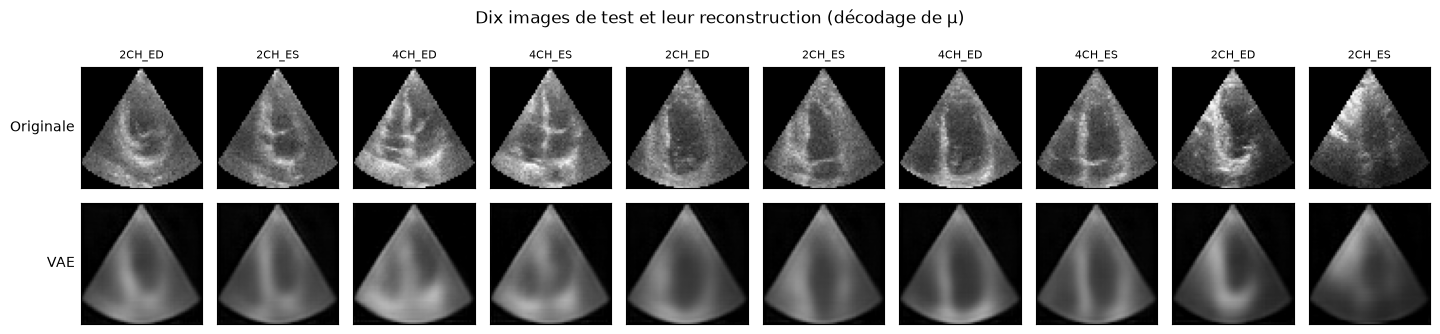

In [12]:
def make_ssim():
    return SSIMMetric(spatial_dims=2, data_range=1.0, win_size=7, reduction="none")


def reconstruction_scores(recon, target):
    error = recon - target
    mae = error.abs().mean(dim=(1, 2, 3)).detach().cpu().numpy()
    mse = error.pow(2).mean(dim=(1, 2, 3)).detach().cpu().numpy()
    psnr = PSNRMetric(max_val=1.0, reduction="none")(recon, target).detach().cpu().numpy().reshape(-1)
    ssim = make_ssim()(recon.clamp(0, 1), target.clamp(0, 1)).detach().cpu().numpy().reshape(-1)
    return mae, mse, psnr, ssim


def mean_std(values):
    values = np.asarray(values, dtype=np.float64)
    return float(np.mean(values)), float(np.std(values))


def fmt_mean_std(values, digits=3):
    mu, sigma = mean_std(values)
    return f"{mu:.{digits}f} ± {sigma:.{digits}f}"


def masked_mse(recon, image, label, inside):
    error = (recon - image).pow(2)
    mask = (label.unsqueeze(1) > 0) if inside else (label.unsqueeze(1) == 0)
    mask = mask.to(error.dtype)
    denom = mask.sum(dim=(1, 2, 3)).clamp_min(1)
    return ((error * mask).sum(dim=(1, 2, 3)) / denom).detach().cpu().numpy()


@torch.no_grad()
def collect_predictions(model, loader):
    model.eval()
    images, recons, labels, mus = [], [], [], []
    view_instants, views, instants, patients = [], [], [], []
    for batch in loader:
        x = batch["image"].to(device)
        mu, sigma = model.encode(x)
        recon = model.decode(mu)
        images.append(batch["image"])
        recons.append(recon.cpu())
        labels.append(batch["label"])
        mus.append(mu.cpu())
        view_instants.extend(list(batch["view_instant"]))
        views.extend(list(batch["view"]))
        instants.extend(list(batch["instant"]))
        patients.extend(list(batch["patient"]))
    packed = {
        "image": torch.cat(images),
        "recon": torch.cat(recons),
        "label": torch.cat(labels),
        "mu": torch.cat(mus),
        "view_instant": np.asarray(view_instants),
        "view": np.asarray(views),
        "instant": np.asarray(instants),
        "patient": np.asarray(patients),
    }
    mae, mse, psnr, ssim = reconstruction_scores(packed["recon"], packed["image"])
    packed.update({"mae": mae, "mse": mse, "psnr": psnr, "ssim": ssim})
    return packed


test_pred = collect_predictions(model, test_loader)
heart_mse = masked_mse(test_pred["recon"], test_pred["image"], test_pred["label"], inside=True)
background_mse = masked_mse(test_pred["recon"], test_pred["image"], test_pred["label"], inside=False)

print(f"MSE moyenne sur les {len(test_dataset)} images de test : {fmt_mean_std(test_pred['mse'], digits=5)}")
print(f"MAE test :  {fmt_mean_std(test_pred['mae'])}")
print(f"PSNR test : {fmt_mean_std(test_pred['psnr'], digits=2)} dB")
print(f"SSIM test : {fmt_mean_std(test_pred['ssim'])}")
print(f"MSE sur le cœur : {fmt_mean_std(heart_mse, digits=5)}")
print(f"MSE sur le fond : {fmt_mean_std(background_mse, digits=5)}")

per_class_rows = []
for view_instant in VIEWS:
    selected = test_pred["view_instant"] == view_instant
    per_class_rows.append([
        view_instant,
        int(selected.sum()),
        f"{mean_std(test_pred['mse'][selected])[0]:.5f}",
        f"{mean_std(test_pred['psnr'][selected])[0]:.2f}",
    ])


def markdown_table(headers, rows):
    lines = [
        "| " + " | ".join(headers) + " |",
        "| " + " | ".join("---" for _ in headers) + " |",
    ]
    for row in rows:
        lines.append("| " + " | ".join(str(cell) for cell in row) + " |")
    return "\n".join(lines)


display(Markdown(
    "### MSE et PSNR de test par vue et par instant\n\n"
    + markdown_table(["Vue / instant", "n", "MSE", "PSNR (dB)"], per_class_rows)
))

n_show = 10
fig, axes = plt.subplots(2, n_show, figsize=(1.45 * n_show, 3.5))
for index in range(n_show):
    axes[0, index].imshow(test_pred["image"][index, 0].numpy(), cmap="gray", vmin=0, vmax=1)
    axes[1, index].imshow(test_pred["recon"][index, 0].clamp(0, 1).numpy(), cmap="gray", vmin=0, vmax=1)
    axes[0, index].set_title(test_pred["view_instant"][index], fontsize=8)
    for row in range(2):
        axes[row, index].set_xticks([])
        axes[row, index].set_yticks([])
axes[0, 0].set_ylabel("Originale", rotation=0, ha="right", va="center")
axes[1, 0].set_ylabel("VAE", rotation=0, ha="right", va="center")
fig.suptitle("Dix images de test et leur reconstruction (décodage de μ)")
fig.tight_layout()
plt.show()

### Espace latent (t-SNE)

t-SNE projette en 2D la moyenne a posteriori de chaque image de test. Le vecteur d'entrée est le μ aplati, de dimension 512. La projection est une visualisation : les distances n'ont de sens que localement. Les points sont colorés par le couple vue / instant. Ces étiquettes ne sont pas dans la perte. Une séparation qui apparaît a été apprise à partir des images seules. Un recouvrement entre ED et ES de la même vue est lui aussi informatif : ce sont deux instants du même cœur, et un code qui les rapproche a gardé l'identité du patient.

Matrice passée à t-SNE : (200, 512) = (images de test, coefficients latents).


Projection t-SNE : (200, 2)


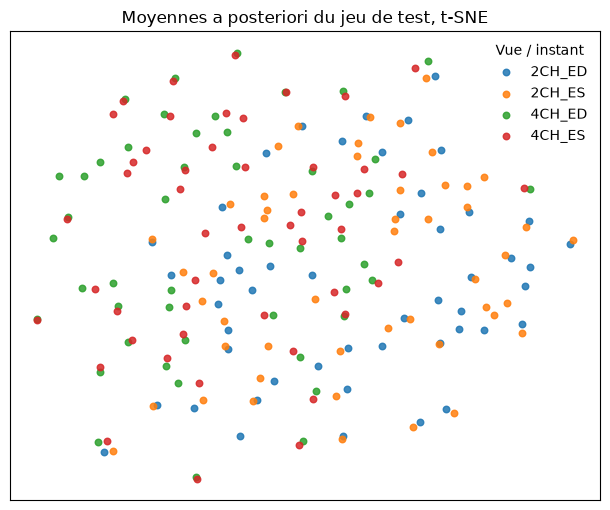

In [13]:
mu_np = test_pred["mu"].numpy()
flat = mu_np.reshape(mu_np.shape[0], -1)
print(f"Matrice passée à t-SNE : {flat.shape} = (images de test, coefficients latents).")
embedding = TSNE(
    n_components=2,
    perplexity=30,
    init="pca",
    random_state=SEED,
).fit_transform(flat)
print(f"Projection t-SNE : {embedding.shape}")

fig, ax = plt.subplots(figsize=(6.2, 5.2))
for view_instant in VIEWS:
    selected = test_pred["view_instant"] == view_instant
    ax.scatter(
        embedding[selected, 0],
        embedding[selected, 1],
        s=22,
        alpha=0.85,
        label=view_instant,
    )
ax.legend(frameon=False, title="Vue / instant")
ax.set_title("Moyennes a posteriori du jeu de test, t-SNE")
ax.set_xticks([])
ax.set_yticks([])
ax.grid(True, color="0.9")
fig.tight_layout()
plt.show()

### Interpolation ED → ES

On prend, dans le jeu de test, la télédiastole et la télésystole d'un même patient et d'une même vue (4 cavités). Les deux moyennes latentes sont interpolées linéairement, puis chaque pas est décodé. Un trajet continu, où la cavité se contracte sans casser le secteur échographique, est la propriété de continuité du VAE, contrôlée sur une paire physiologiquement ordonnée.

L'animation fait l'aller puis le retour. Elle est écrite dans `artifacts/exp2_interp_ED_ES.gif` avec `FuncAnimation` et le writer Pillow. La bande statique ci-dessous est la version lisible dans le notebook.

patient0010 4CH : interpolation de μ_ED vers μ_ES, 16 pas.
GIF aller-retour enregistré dans artifacts/exp2_interp_ED_ES.gif.


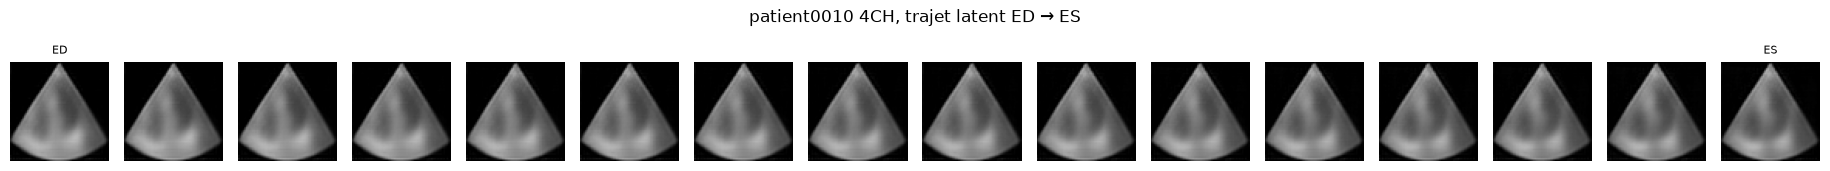

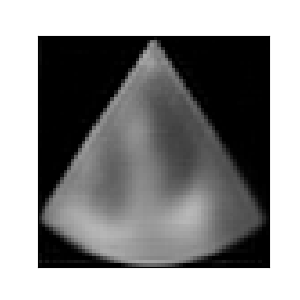

In [14]:
def pair_index(dataset):
    pairs = {}
    for index, record in enumerate(dataset.records):
        pairs.setdefault((record["patient"], record["view"]), {})[record["instant"]] = index
    return pairs


def encode_mu(model, dataset, index):
    image = dataset[index]["image"][None].to(device)
    with torch.no_grad():
        mu, _ = model.encode(image)
    return mu


def interpolate(model, z0, z1, steps):
    weights = torch.linspace(0, 1, steps, device=z0.device)
    codes = torch.cat([torch.lerp(z0, z1, float(weight)) for weight in weights], dim=0)
    with torch.no_grad():
        frames = model.decode(codes)[:, 0].cpu().clamp(0, 1).numpy()
    return frames


def save_gif(frames, path, fps=8):
    fig, ax = plt.subplots(figsize=(3, 3))
    shown = ax.imshow(frames[0], cmap="gray", vmin=0, vmax=1)
    ax.set_xticks([])
    ax.set_yticks([])

    def update(frame_index):
        shown.set_data(frames[frame_index])
        return [shown]

    animation = FuncAnimation(fig, update, frames=len(frames), interval=1000 / fps, blit=True)
    animation.save(path, writer="pillow", fps=fps)
    plt.close(fig)
    return animation


pairs = pair_index(test_dataset)
ed_index, es_index, gif_patient, gif_view = next(
    (indexes["ED"], indexes["ES"], patient, view)
    for (patient, view), indexes in pairs.items()
    if "ED" in indexes and "ES" in indexes and view == "4CH"
)

z_ed = encode_mu(model, test_dataset, ed_index)
z_es = encode_mu(model, test_dataset, es_index)
forward = interpolate(model, z_ed, z_es, steps=16)
cycle = np.concatenate([forward, forward[-2:0:-1]], axis=0)

gif_path = ARTIFACT_DIR / "exp2_interp_ED_ES.gif"
save_gif(cycle, gif_path, fps=8)
print(f"{gif_patient} {gif_view} : interpolation de μ_ED vers μ_ES, {forward.shape[0]} pas.")
print(f"GIF aller-retour enregistré dans {gif_path}.")

fig, axes = plt.subplots(1, forward.shape[0], figsize=(1.15 * forward.shape[0], 1.8))
for ax, frame in zip(axes, forward):
    ax.imshow(frame, cmap="gray", vmin=0, vmax=1)
    ax.axis("off")
axes[0].set_title("ED", fontsize=8)
axes[-1].set_title("ES", fontsize=8)
fig.suptitle(f"{gif_patient} {gif_view}, trajet latent ED → ES")
fig.tight_layout()
plt.show()

display(Image(filename=str(gif_path)))

### Comparaison avec l'expérience 1

La colonne de l'expérience 1 est lue dans `artifacts/results.json`, produit par `assignment-2-camus.ipynb`. Les métriques de test (MSE, PSNR, SSIM) sont définies de la même façon dans les deux notebooks. Le nombre de paramètres de l'expérience 1 est recompté en instanciant la même architecture, sans l'entraîner.

Cette comparaison mêle plusieurs changements à la fois : largeur du réseau, taille du latent, L1 ou MSE, montée de β, calendrier d'apprentissage. Un écart de MSE ne s'attribue donc pas à un seul facteur. Il dit si l'ensemble des choix de l'expérience 2 reconstruit mieux ou moins bien les patients de test.

In [15]:
def count_parameters(net):
    return sum(parameter.numel() for parameter in net.parameters())


exp1_model = AutoencoderKL(
    spatial_dims=2,
    in_channels=1,
    out_channels=1,
    num_res_blocks=1,
    channels=(16, 32, 64, 64),
    attention_levels=(False, False, False, False),
    latent_channels=4,
    norm_num_groups=16,
    with_encoder_nonlocal_attn=False,
    with_decoder_nonlocal_attn=False,
)
exp1_params = count_parameters(exp1_model)
del exp1_model

exp1_path = ARTIFACT_DIR / "results.json"
exp1_report = None
if exp1_path.is_file():
    exp1_report = json.loads(exp1_path.read_text())
    exp1_test = next(row for row in exp1_report["test"] if str(row["name"]).startswith("VAE"))
    exp1_latent = "×".join(str(value) for value in exp1_report["latent_shape"])
    comparison_rows = [[
        "Expérience 1",
        exp1_latent,
        "L1 + β KL",
        f"{exp1_report['selected_beta']:.0e}",
        f"{exp1_params:,}",
        exp1_test["mse"],
        exp1_test["psnr"],
        exp1_test["ssim"],
    ]]
else:
    exp1_test = None
    comparison_rows = []
    print(f"{exp1_path} est absent. La colonne de l'expérience 1 n'est pas remplie.")

comparison_rows.append([
    "Expérience 2",
    "×".join(str(value) for value in LATENT_SHAPE),
    "MSE + β KL",
    f"{BETA:.0e}",
    f"{N_PARAMS:,}",
    fmt_mean_std(test_pred["mse"], digits=5),
    fmt_mean_std(test_pred["psnr"], digits=2),
    fmt_mean_std(test_pred["ssim"]),
])

display(Markdown(
    "### Test, expérience 1 et expérience 2\n\n"
    + markdown_table(
        ["Expérience", "Latent", "Perte", "β", "Paramètres", "MSE test", "PSNR (dB)", "SSIM"],
        comparison_rows,
    )
))

mse_mean, mse_std = mean_std(test_pred["mse"])
psnr_mean, psnr_std = mean_std(test_pred["psnr"])
ssim_mean, ssim_std = mean_std(test_pred["ssim"])
mae_mean, mae_std = mean_std(test_pred["mae"])
heart_mean, heart_std = mean_std(heart_mse)
background_mean, background_std = mean_std(background_mse)

results_exp2 = {
    "experiment": 2,
    "beta": BETA,
    "recon_loss": "mse",
    "channels": list(CHANNELS),
    "latent_shape": list(LATENT_SHAPE),
    "n_params": N_PARAMS,
    "epochs": history["epochs"],
    "best_epoch": history["best_epoch"],
    "best_val": history["best_val"],
    "seconds": history["seconds"],
    "seed": SEED,
    "test": {
        "n": len(test_dataset),
        "mse_mean": mse_mean,
        "mse_std": mse_std,
        "mae_mean": mae_mean,
        "mae_std": mae_std,
        "psnr_mean": psnr_mean,
        "psnr_std": psnr_std,
        "ssim_mean": ssim_mean,
        "ssim_std": ssim_std,
        "heart_mse_mean": heart_mean,
        "heart_mse_std": heart_std,
        "background_mse_mean": background_mean,
        "background_mse_std": background_std,
    },
}
if exp1_report is not None:
    results_exp2["experiment_1"] = {
        "source": str(exp1_path),
        "beta": exp1_report["selected_beta"],
        "latent_shape": exp1_report["latent_shape"],
        "recon_loss": "l1",
        "n_params": exp1_params,
        "test_row": exp1_test,
    }

results_path = ARTIFACT_DIR / "results_exp2.json"
results_path.write_text(json.dumps(results_exp2, indent=2))
print(f"Résultats écrits dans {results_path}.")
print(
    f"Expérience 2 — meilleure époque {history['best_epoch']}/{history['epochs']}, "
    f"MSE test {mse_mean:.5f}, PSNR {psnr_mean:.2f} dB, SSIM {ssim_mean:.3f}."
)

### Test, expérience 1 et expérience 2

| Expérience | Latent | Perte | β | Paramètres | MSE test | PSNR (dB) | SSIM |
| --- | --- | --- | --- | --- | --- | --- | --- |
| Expérience 1 | 4×8×8 | L1 + β KL | 1e-04 | 473,649 | 0.01024 ± 0.01093 | 20.97 ± 2.68 | 0.622 ± 0.070 |
| Expérience 2 | 8×8×8 | MSE + β KL | 1e-04 | 1,888,449 | 0.00765 ± 0.00538 | 21.70 ± 1.92 | 0.445 ± 0.065 |

Résultats écrits dans artifacts/results_exp2.json.
Expérience 2 — meilleure époque 19/20, MSE test 0.00765, PSNR 21.70 dB, SSIM 0.445.


## Conclusion

Les deux expériences sont comparables sur le jeu de test : mêmes patients, mêmes images dans [0, 1], mêmes définitions du PSNR et du SSIM. Elles diffèrent par le terme de reconstruction (MSE ici, L1 dans l'expérience 1), par le code latent (512 coefficients contre 256), par la largeur du réseau, par l'absence de montée progressive de β, et par un pas d'apprentissage constant. Le tableau ci-dessus donne le résultat de cet ensemble de choix. Il ne suffit pas à attribuer un écart à un seul d'entre eux.

La MSE globale se lit avec la MSE sur le cœur. Le fond noir occupe la majorité des pixels et tire l'erreur vers le bas. Le t-SNE dit si le code a organisé la vue et l'instant sans qu'on le lui demande. Le GIF dit si le segment entre la télédiastole et la télésystole du même cœur reste une image d'échographie plausible.

Limites de cette itération. Une seule graine, vingt époques, CPU. Seuls les instants ED et ES sont vus : le trajet latent teste une interpolation, il ne modélise pas le cycle cardiaque. Le décodeur MSE, comme le décodeur L1, produit une moyenne conditionnelle, donc un bord endocardique lisse et un speckle moyenné.

Itération suivante, un facteur à la fois. Reprendre l'architecture de l'expérience 1 et ne changer que L1 en MSE. Ou garder cette architecture et refaire la grille de β de l'expérience 1, avec la montée progressive sur le premier quart des époques si la KL s'effondre dès les premières époques. Croiser ensuite la largeur du réseau et la taille du latent, une fois le terme de reconstruction fixé.